# 02 · Explore behavior and test useful hypotheses

**Credit Risk Lab | IBM stages 5–6: data understanding → data preparation**

All outcome-aware exploration in this notebook uses the saved training partition. The questions are declared before the calculations. P-values assess compatibility with a statistical null under assumptions; they do not establish practical value, causality, or future model performance.

In [1]:
from pathlib import Path
import json
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "src" / "credit_risk").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the credit-risk-lab project.")
sys.path.insert(0, str(ROOT / "src"))
required = [ROOT / "data/processed/credit.csv", ROOT / "reports/split_manifest.csv"]
if not all(p.exists() for p in required):
    raise FileNotFoundError("Run `python -m credit_risk.run --root .` from the project root first.")
credit = pd.read_csv(required[0])
manifest = pd.read_csv(required[1])
assert credit["id"].is_unique and manifest["id"].is_unique
assert set(credit.id) == set(manifest.id)
assert set(manifest["split"]) == {"train", "validation", "test"}
train_ids = set(manifest.loc[manifest["split"].eq("train"), "id"])
train = credit.loc[credit.id.isin(train_ids)].copy()
sns.set_theme(style="whitegrid", palette=["#008b83", "#173c57", "#d58045", "#7869a7"])
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.options.display.float_format = "{:,.4f}".format
display(pd.DataFrame({"partition": manifest["split"].value_counts().index,
                      "accounts": manifest["split"].value_counts().values}))

,partition,accounts
0,train,18000
1,test,6000
2,validation,6000


## 1. Establish the training base rate

A prevalence baseline gives context to precision–recall metrics. Class imbalance alone does not justify manufacturing observations or choosing a recall target without an operational reason.

,accounts,share
target,,
No recorded next-month default,14018,0.7788
Recorded next-month default,3982,0.2212


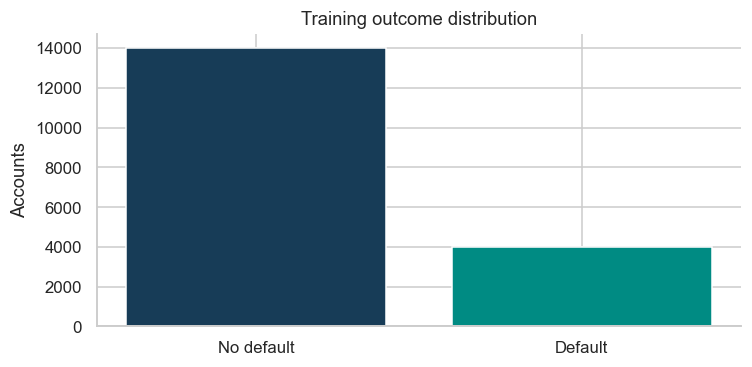

In [2]:
base = train.groupby("target").size().rename("accounts").to_frame()
base["share"] = base.accounts / len(train)
display(base.rename(index={0: "No recorded next-month default", 1: "Recorded next-month default"}))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["No default", "Default"], base.accounts, color=["#173c57", "#008b83"])
ax.set(title="Training outcome distribution", ylabel="Accounts")
plt.tight_layout()
plt.show()

## 2. Hypothesis A: recorded payment delays carry predictive information

**Question:** is the training default rate higher among accounts with at least one positive delay code? Define a positive delay explicitly (`status > 0`); do not label ambiguous negative or zero codes as delinquency. Report counts and the observed risk difference alongside the chi-square test.

In [3]:
from scipy.stats import chi2_contingency, mannwhitneyu
from credit_risk.features import STATUS, BILLS, PAYMENTS, CreditFeatures

train["any_positive_delay"] = train[STATUS].gt(0).any(axis=1)
delay_table = pd.crosstab(train["any_positive_delay"], train["target"]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
chi2, p_value, dof, expected = chi2_contingency(delay_table, correction=False)
rates = train.groupby("any_positive_delay")["target"].agg(accounts="size", defaults="sum", default_rate="mean")
risk_difference = rates.loc[True, "default_rate"] - rates.loc[False, "default_rate"]
display(rates)
display(pd.Series({"chi_square": chi2, "degrees_of_freedom": dof, "p_value": p_value,
                   "phi_effect_size": np.sqrt(chi2 / len(train)),
                   "observed_risk_difference": risk_difference,
                   "smallest_expected_cell_count": expected.min()}, name="hypothesis_A").to_frame())

,accounts,defaults,default_rate
any_positive_delay,,,
False,11902,1361,0.1144
True,6098,2621,0.4298


,hypothesis_A
chi_square,"2,329.0999"
degrees_of_freedom,1.0000
p_value,0.0000
phi_effect_size,0.3597
observed_risk_difference,0.3155
smallest_expected_cell_count,"1,349.0131"


**Interpretation guide:** the sign and magnitude of the risk difference are easier to translate into a portfolio question than a small p-value alone. Phi describes association strength for this binary table. Neither measure isolates a treatment effect or controls confounding. This is exploratory evidence, with no multiple-testing-adjusted discovery claim.

,accounts,default_rate
delayed_months,,
0,11902,0.1144
1,2657,0.2992
2,1167,0.3993
3,719,0.4979
4,573,0.5742
5,169,0.6213
6,813,0.6986


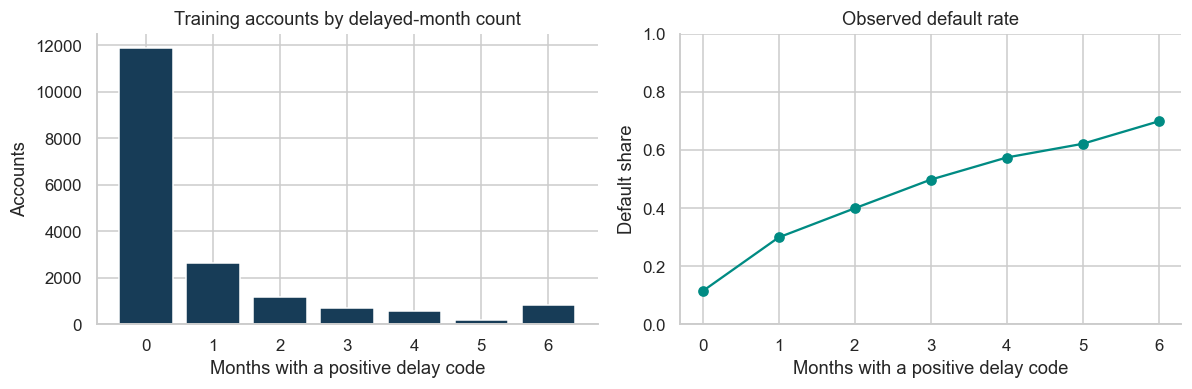

In [4]:
by_count = train.assign(delayed_months=train[STATUS].gt(0).sum(axis=1)).groupby("delayed_months")["target"].agg(accounts="size", default_rate="mean")
display(by_count)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(by_count.index, by_count.accounts, color="#173c57")
axes[0].set(title="Training accounts by delayed-month count", xlabel="Months with a positive delay code", ylabel="Accounts")
axes[1].plot(by_count.index, by_count.default_rate, marker="o", color="#008b83")
axes[1].set(title="Observed default rate", xlabel="Months with a positive delay code", ylabel="Default share", ylim=(0, 1))
plt.tight_layout()
plt.show()

## 3. Hypothesis B: credit-limit distributions differ by outcome

Credit limits are skewed, so show distributions and medians. A two-sided Mann–Whitney comparison tests a distributional relationship, not necessarily a difference in means or medians. Rank-biserial correlation summarizes directional rank separation. A high-powered test in a large dataset can find a small association.

,accounts,median,mean
target,,,
0,14018,"150,000.0000","178,564.1318"
1,3982,"90,000.0000","129,593.1693"


,hypothesis_B
Mann_Whitney_U,"21,153,954.0000"
p_value,0.0000
rank_biserial_default_minus_other,-0.2421


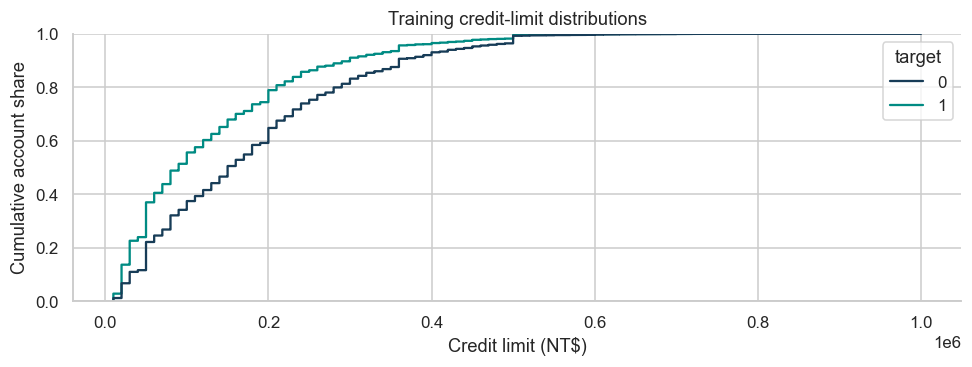

In [5]:
default_limits = train.loc[train.target.eq(1), "limit_bal"]
other_limits = train.loc[train.target.eq(0), "limit_bal"]
u, p_limit = mannwhitneyu(default_limits, other_limits, alternative="two-sided", method="asymptotic")
rank_biserial = 2 * u / (len(default_limits) * len(other_limits)) - 1
display(train.groupby("target")["limit_bal"].agg(accounts="size", median="median", mean="mean"))
display(pd.Series({"Mann_Whitney_U": u, "p_value": p_limit,
                   "rank_biserial_default_minus_other": rank_biserial}, name="hypothesis_B").to_frame())
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.ecdfplot(data=train, x="limit_bal", hue="target", palette=["#173c57", "#008b83"], ax=ax)
ax.set(title="Training credit-limit distributions", xlabel="Credit limit (NT$)", ylabel="Cumulative account share")
plt.tight_layout()
plt.show()

## 4. Correlation and repeated monthly measurements

Bills and payments from adjacent months are related measurements, not six independent customer samples. Correlation is useful for diagnosing redundancy and regularization needs. It does not establish causality, and a linear correlation matrix cannot capture every nonlinear relationship.

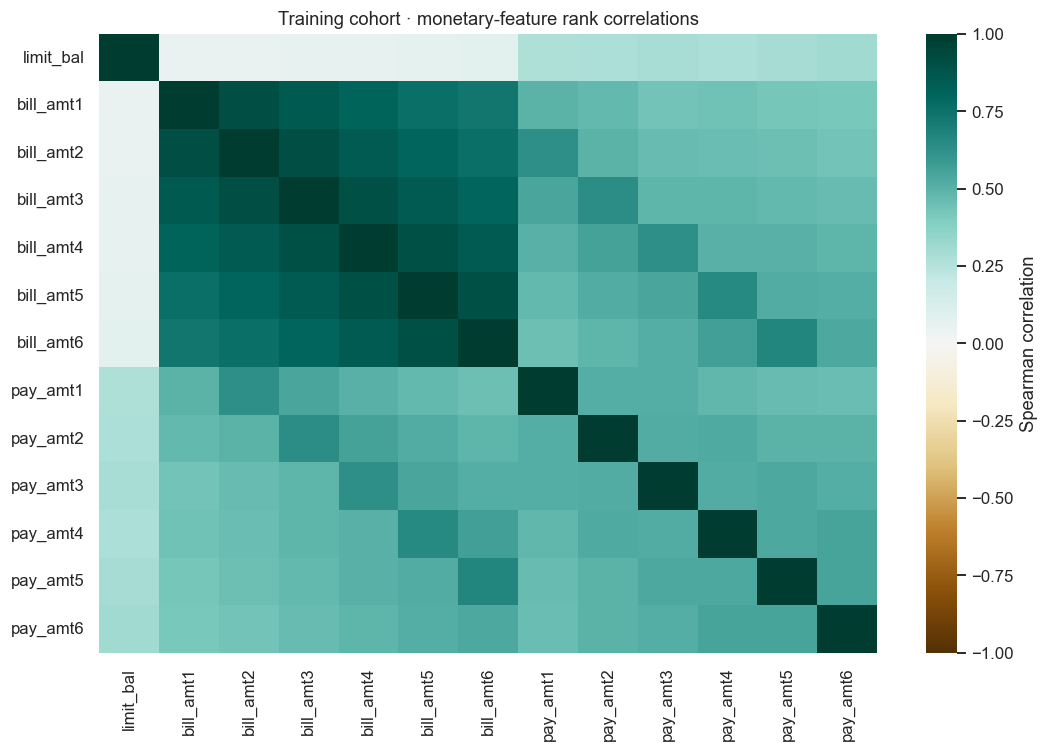

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train[["limit_bal", *BILLS, *PAYMENTS]].corr(method="spearman"),
            cmap="BrBG", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Training cohort · monetary-feature rank correlations")
plt.tight_layout()
plt.show()

## 5. Inspect deterministic behavioral features

The transformer keeps a strict predictor allowlist. It adds summaries without learning from outcomes. Safe division produces a missing value when a denominator is zero; downstream imputation is fitted **inside training folds**. Negative bill amounts remain in the source; positive-delay summaries clip only the status code before summarizing delay severity.

In [7]:
engineered = CreditFeatures(engineered=True).fit_transform(train)
assert not {"id", "target", "sex", "age"}.intersection(engineered.columns)
numeric_engineered = engineered.select_dtypes("number")
assert not np.isinf(numeric_engineered.to_numpy(dtype=float)).any()
selected = ["delayed_month_count", "max_delay", "mean_bill", "mean_payment",
            "latest_balance_to_limit", "payment_to_abs_bill", "zero_payment_months"]
display(engineered[selected].describe().T)
display(engineered[selected].isna().sum().rename("undefined_ratio_or_missing_values").to_frame())

,count,mean,std,min,25%,50%,75%,max
delayed_month_count,"18,000.0000",0.8424,1.5579,0.0000,0.0000,0.0000,1.0000,6.0000
max_delay,"18,000.0000",0.6872,1.0703,0.0000,0.0000,0.0000,2.0000,8.0000
mean_bill,"18,000.0000","45,259.2995","63,607.7441","-20,913.3333","4,861.3333","21,101.0000","57,369.0833","877,313.8333"
mean_payment,"18,000.0000","5,307.0181","10,311.5344",0.0000,"1,117.3333","2,420.1667","5,680.0417","627,344.3333"
latest_balance_to_limit,"18,000.0000",0.4243,0.4109,-0.6199,0.0223,0.3170,0.8299,6.4553
payment_to_abs_bill,"17,483.0000",0.4991,7.0027,0.0000,0.0426,0.0964,0.6177,797.0000
zero_payment_months,"18,000.0000",1.2287,1.7132,0.0000,0.0000,0.0000,2.0000,6.0000


,undefined_ratio_or_missing_values
delayed_month_count,0
max_delay,0
mean_bill,0
mean_payment,0
latest_balance_to_limit,0
payment_to_abs_bill,517
zero_payment_months,0


## 6. Record the modeling implications

- Compare a regularized linear boundary with nonlinear classifiers; correlated monthly measurements justify regularization.
- Use suitable scaling for logistic regression and SVM; fit it within each training fold.
- Test engineered summaries with a controlled ablation rather than assuming they help.
- Keep categorical source codes distinct instead of treating every integer as an ordinal scale.
- Evaluate ranking and probability quality separately, then translate probabilities into a stated review policy.

These analyses motivate hypotheses. The validation comparison in notebook 03 determines which choices earned support. No test-set outcome was needed to create these plots or statistical comparisons.